# 03 — Inventory surprise: таргет проекта

Целевая переменная проекта — **сюрприз запасов** `surprise = actual ΔStocks − consensus`
(коммерческие запасы нефти США без SPR, млн барр.; `> 0` — запасы выросли сильнее ожиданий).
Здесь собираем ряд таргета, проверяем, какой «факт» брать, насколько хорош консенсус,
что добавляет API и насколько сюрприз вообще предсказуем по истории.

Данные: `consensus/myfxbook_eia_consensus.parquet` (факт первой публикации и консенсус),
`eia/eia_weekly_features.parquet` (пересмотренные данные EIA),
`consensus/trendonify_api_crude_full_history.parquet` (API, выходит во вторник до EIA).
Таблицу собирает `eda_utils.release_frame()`.

Разбиение по времени, общее для всех ноутбуков EDA: **train — релизы до 2022-12-31,
test — с 2023-01-01**.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

import eda_utils as u

u.setup_style()
SPLIT = pd.Timestamp("2023-01-01")
frame = u.release_frame()
frame["is_test"] = frame["release_date"] >= SPLIT
frame["week"] = frame["period"].dt.isocalendar().week.astype(int)
frame["year"] = frame["release_date"].dt.year
frame.head()

,release_date,actual_mmbbl,consensus_mmbbl,surprise_mmbbl,period,eia_change_mmbbl,api_mmbbl,is_test,week,year
0,2015-01-07,-3.062,0.90,-3.962,2015-01-02,NaN,-4.0,False,1,2015
1,2015-01-14,5.400,0.40,5.000,2015-01-09,NaN,3.9,False,2,2015
2,2015-01-22,10.070,2.60,7.470,2015-01-16,NaN,5.7,False,3,2015
3,2015-01-28,8.874,3.80,5.074,2015-01-23,NaN,12.7,False,4,2015
4,2015-02-04,6.333,3.75,2.583,2015-01-30,NaN,6.1,False,5,2015


## 1. Ряд таргета и календарь релизов

Релиз EIA выходит в среду за неделю, закончившуюся в пятницу; праздники сдвигают его.
Неделю отчёта считаем как «последняя пятница не позже релиза минус 5 дней».

In [2]:
weekday_names = {0: "пн", 1: "вт", 2: "ср", 3: "чт", 4: "пт"}
calendar = pd.DataFrame(
    {
        "релизов": frame["release_date"].dt.day_of_week.map(weekday_names).value_counts(),
    },
)
calendar["дней от конца недели"] = (
    frame.assign(day=frame["release_date"].dt.day_of_week.map(weekday_names))
    .groupby("day")
    .apply(lambda g: sorted((g["release_date"] - g["period"]).dt.days.unique()), include_groups=False)
)
print(f"Релизов: {len(frame)}, {frame['release_date'].min():%Y-%m-%d} – {frame['release_date'].max():%Y-%m-%d}")
print(f"Повторов недели отчёта: {frame['period'].duplicated().sum()}")
gaps = frame["period"].diff().dt.days.value_counts().sort_index()
print("Шаг между неделями отчёта, дней:", gaps.to_dict())
calendar

Релизов: 616, 2015-01-07 – 2026-11-04
Повторов недели отчёта: 0
Шаг между неделями отчёта, дней: {7.0: 613, 14.0: 2}


,релизов,дней от конца недели
release_date,,
ср,526,[5]
чт,83,[6]
пт,6,[7]
пн,1,[10]


In [3]:
missing_weeks = pd.date_range(frame["period"].min(), frame["period"].max(), freq="W-FRI").difference(frame["period"])
print("Недели без релиза в Myfxbook:", [f"{d:%Y-%m-%d}" for d in missing_weeks])

Недели без релиза в Myfxbook: ['2022-06-17', '2023-11-03']


**Вывод.** 616 релизов, 2015-01-07 – 2026-11-04: 526 в среду, 83 в четверг, 6 в пятницу и один
в понедельник (2025-12-29 — отчёт за неделю до 19 декабря, сдвиг из-за Рождества). Правило
«пятница не позже релиза минус 5 дней» даёт неделю отчёта без повторов. В Myfxbook нет двух недель
отчёта: 2022-06-17 и 2023-11-03 — на этих местах шаг 14 дней, и «прошлая неделя» в лагах на самом
деле позапрошлая. Даты совпадают с известными задержками EIA (сбой систем в июне 2022, перенос
публикации в ноябре 2023) — стоит сверить с архивом EIA.

## 2. Какой «факт» брать: первая публикация или пересмотренные данные

`actual_mmbbl` в Myfxbook — значение в день релиза. `eia_change_mmbbl` — изменение по
текущим данным EIA API: EIA уточняет уровни прошлых недель, поэтому значения могут
расходиться. Рынок реагирует на первую публикацию.

In [4]:
both = frame.dropna(subset=["eia_change_mmbbl"]).copy()
both["revision"] = both["eia_change_mmbbl"] - both["actual_mmbbl"]
bins = pd.cut(both["revision"].abs(), [-0.001, 0.05, 0.5, 100], labels=["< 0.05", "0.05–0.5", "≥ 0.5"])
print(f"Недель с обоими значениями: {len(both)}")
print(bins.value_counts().sort_index().to_string())
print(f"Корреляция: {both['actual_mmbbl'].corr(both['eia_change_mmbbl']):.4f}")
both.loc[both["revision"].abs() >= 0.05, ["release_date", "period", "actual_mmbbl", "eia_change_mmbbl", "revision"]].round({"actual_mmbbl": 3, "eia_change_mmbbl": 3, "revision": 3})

Недель с обоими значениями: 607
revision
< 0.05      590
0.05–0.5     11
≥ 0.5         6
Корреляция: 0.9997


,release_date,period,actual_mmbbl,eia_change_mmbbl,revision
9,2015-03-11,2015-03-06,4.512,5.179,0.667
13,2015-04-08,2015-04-03,10.949,11.679,0.730
17,2015-05-06,2015-05-01,-3.882,-4.102,-0.220
22,2015-06-10,2015-06-05,-6.812,-6.017,0.795
26,2015-07-08,2015-07-03,0.384,0.491,0.107
31,2015-08-12,2015-08-07,-1.682,-1.404,0.278
35,2015-09-10,2015-09-04,2.570,2.405,-0.165
44,2015-11-12,2015-11-06,4.224,3.981,-0.243
48,2015-12-09,2015-12-04,-3.568,-3.659,-0.091
52,2016-01-06,2016-01-01,-5.085,-4.150,0.935


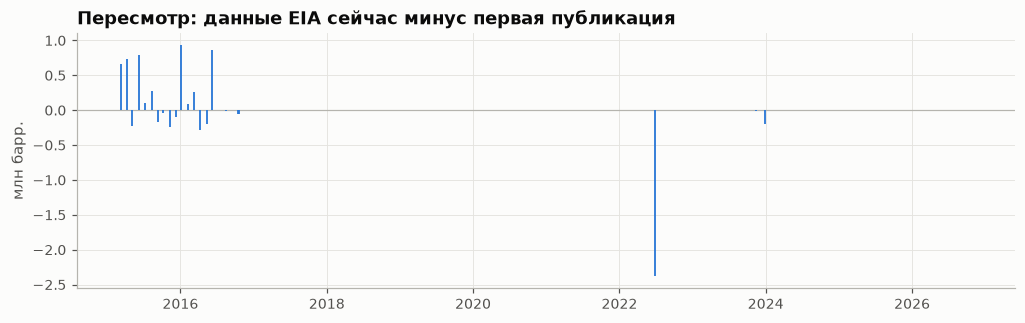

In [5]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.axhline(0, color=u.NEUTRAL, linewidth=0.8)
ax.vlines(both["release_date"], 0, both["revision"], color=u.SERIES[0], linewidth=1.2)
ax.set_title("Пересмотр: данные EIA сейчас минус первая публикация")
ax.set_ylabel("млн барр.")
plt.show()

**Вывод.** Из 607 недель с обоими значениями 590 совпадают с точностью 0.05 млн барр.,
11 расходятся на 0.05–0.5, 6 — на 0.5 и больше (corr 0.9997). 15 из 17 расхождений приходятся
на 2015 – середину 2016 и идут примерно раз в месяц; позже расходятся только 2022-06-29 (−2.38,
неделя после сбоя EIA — проверить вручную) и 2023-12-28 (−0.20). Таргет считаем по первой
публикации (`actual_mmbbl` Myfxbook): на неё реагирует рынок. Лаговые признаки «прошлый факт»
тоже нужно брать из первой публикации, иначе в них попадает будущий пересмотр.

## 3. Консенсус

Насколько консенсус похож на факт, есть ли у него смещение и как он округлён.

In [6]:
desc = frame[["actual_mmbbl", "consensus_mmbbl", "surprise_mmbbl"]].describe().T
desc["skew"] = frame[["actual_mmbbl", "consensus_mmbbl", "surprise_mmbbl"]].skew()
desc["kurtosis"] = frame[["actual_mmbbl", "consensus_mmbbl", "surprise_mmbbl"]].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
actual_mmbbl,616.0,0.07,5.38,-17.05,-3.53,-0.39,3.38,21.56,0.39,0.84
consensus_mmbbl,616.0,-0.26,2.40,-5.26,-2.05,-0.70,1.38,15.15,1.09,3.75
surprise_mmbbl,616.0,0.34,4.73,-15.68,-2.64,-0.00,3.27,22.49,0.41,1.80


In [7]:
step = (frame["consensus_mmbbl"] * 1000).round().astype(int)
print("Доля консенсусов, кратных 0.1 млн барр.:", f"{(step % 100 == 0).mean():.1%}")
print("Доля кратных 0.5 млн барр.:", f"{(step % 500 == 0).mean():.1%}")
print("Самые частые значения консенсуса:")
print(frame["consensus_mmbbl"].round(3).value_counts().head(8).to_string())

Доля консенсусов, кратных 0.1 млн барр.: 33.0%
Доля кратных 0.5 млн барр.: 10.9%
Самые частые значения консенсуса:
consensus_mmbbl
-2.0    14
-1.1     8
 0.4     6
 3.0     6
-1.6     6
 2.6     5
 2.3     5
-0.9     5


                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.3558      0.192      1.856      0.064      -0.021       0.732
consensus_mmbbl     1.0725      0.079     13.525      0.000       0.917       1.228
R² = 0.230


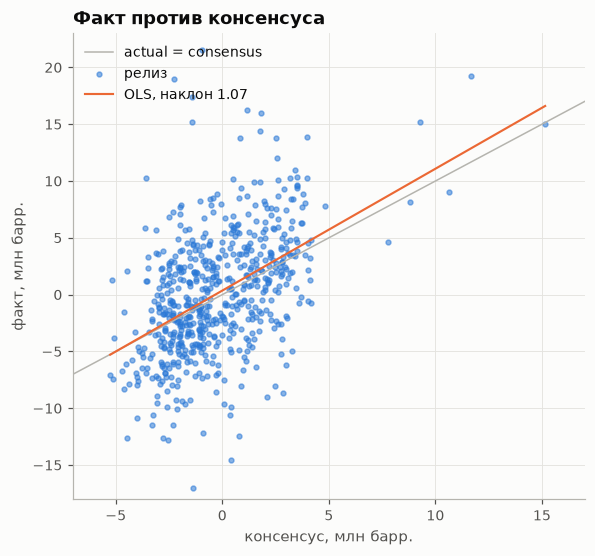

In [8]:
fit = sm.OLS(frame["actual_mmbbl"], sm.add_constant(frame["consensus_mmbbl"])).fit()
print(fit.summary().tables[1])
print(f"R² = {fit.rsquared:.3f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
lim = (-18, 23)
ax.plot(lim, lim, color=u.NEUTRAL, linewidth=1, label="actual = consensus")
ax.scatter(frame["consensus_mmbbl"], frame["actual_mmbbl"], s=10, alpha=0.55, color=u.SERIES[0], label="релиз")
grid = np.linspace(frame["consensus_mmbbl"].min(), frame["consensus_mmbbl"].max(), 10)
ax.plot(grid, fit.params["const"] + fit.params["consensus_mmbbl"] * grid, color=u.SERIES[1], label=f"OLS, наклон {fit.params['consensus_mmbbl']:.2f}")
ax.set_xlim(-7, 17)
ax.set_ylim(*lim)
ax.set_xlabel("консенсус, млн барр.")
ax.set_ylabel("факт, млн барр.")
ax.set_title("Факт против консенсуса")
ax.legend(loc="upper left")
plt.show()

In [9]:
yearly = frame.groupby("year").agg(
    релизов=("surprise_mmbbl", "size"),
    факт_std=("actual_mmbbl", "std"),
    консенсус_std=("consensus_mmbbl", "std"),
    сюрприз_среднее=("surprise_mmbbl", "mean"),
    сюрприз_медиана=("surprise_mmbbl", "median"),
    сюрприз_std=("surprise_mmbbl", "std"),
    доля_выше_ожиданий=("surprise_mmbbl", lambda s: (s > 0).mean()),
    corr_факт_консенсус=("actual_mmbbl", lambda s: s.corr(frame.loc[s.index, "consensus_mmbbl"])),
)
yearly.round(2)

,релизов,факт_std,консенсус_std,сюрприз_среднее,сюрприз_медиана,сюрприз_std,доля_выше_ожиданий,corr_факт_консенсус
year,,,,,,,,
2015,52,4.85,2.38,0.95,0.83,3.78,0.58,0.64
2016,52,4.75,2.36,-0.26,-0.08,4.47,0.50,0.36
2017,52,4.89,2.61,-0.02,-0.56,3.54,0.44,0.71
2018,52,5.10,2.45,0.70,0.53,4.28,0.54,0.55
2019,52,5.63,2.08,0.38,0.86,5.06,0.58,0.44
2020,53,6.75,4.02,0.19,-0.88,5.34,0.47,0.61
2021,52,5.61,2.07,0.07,-0.98,5.17,0.37,0.39
2022,51,4.92,1.52,0.35,-0.66,5.02,0.47,0.09
2023,51,6.66,1.42,0.64,0.07,6.31,0.51,0.35


**Вывод.** Консенсус в 2.2 раза глаже факта (std 2.40 против 5.38 млн барр.) и объясняет
только 23% дисперсии факта (R² = 0.23, corr 0.48). Наклон «факт ~ консенсус» 1.07 (95% ДИ
0.92–1.23): по масштабу консенсус не смещён; свободный член +0.36 (p = 0.064) — слабый намёк на
недооценку приростов. Лишь 33% значений кратны 0.1 млн барр.: это среднее по опросу, а не одна
круглая оценка. Главное — информативность консенсуса падает: корреляция с фактом 0.64–0.71 в
2015 и 2017, 0.09 в 2022 и 0.35–0.39 в 2023–2026. Разброс консенсуса сжался (std 1.4–2.0 после
2021), разброс факта — нет.

## 4. Распределение и динамика сюрприза

среднее 0.337, медиана -0.002, std 4.728
асимметрия 0.41, эксцесс 1.80; Jarque–Bera p = 4.3e-22
t-тест среднего = 0: t = 1.77, p = 0.078
доля сюрпризов > 0: 50.0%; |s| > 5: 26.0%; |s| > 10: 3.2%
квантили: {0.01: -10.9, 0.05: -6.86, 0.25: -2.64, 0.5: -0.0, 0.75: 3.27, 0.95: 7.68, 0.99: 13.7}


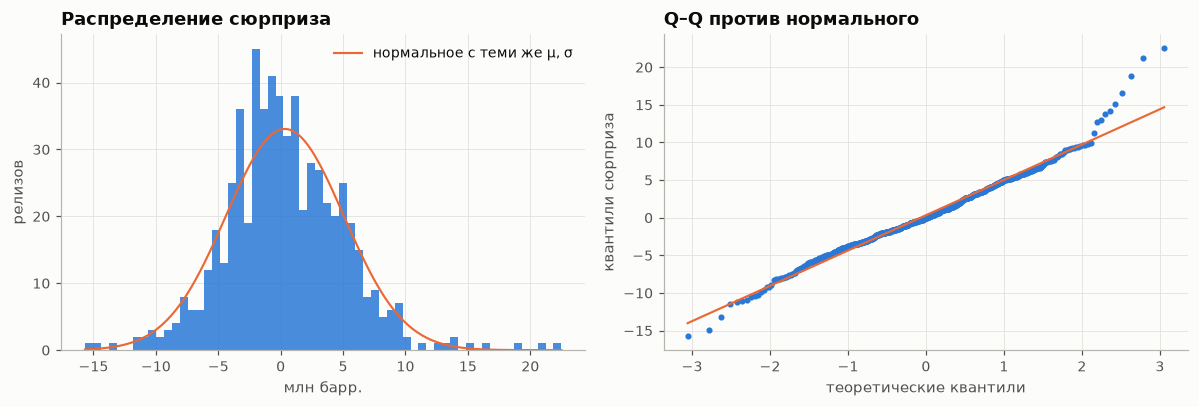

In [10]:
s = frame["surprise_mmbbl"]
jb = stats.jarque_bera(s)
t_mean = stats.ttest_1samp(s, 0)
print(f"среднее {s.mean():.3f}, медиана {s.median():.3f}, std {s.std():.3f}")
print(f"асимметрия {s.skew():.2f}, эксцесс {s.kurt():.2f}; Jarque–Bera p = {jb.pvalue:.1e}")
print(f"t-тест среднего = 0: t = {t_mean.statistic:.2f}, p = {t_mean.pvalue:.3f}")
print(f"доля сюрпризов > 0: {(s > 0).mean():.1%}; |s| > 5: {(s.abs() > 5).mean():.1%}; |s| > 10: {(s.abs() > 10).mean():.1%}")
print("квантили:", s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(s, bins=60, color=u.SERIES[0], alpha=0.85)
x = np.linspace(s.min(), s.max(), 200)
axes[0].plot(x, stats.norm.pdf(x, s.mean(), s.std()) * len(s) * (s.max() - s.min()) / 60, color=u.SERIES[1], label="нормальное с теми же μ, σ")
axes[0].set_title("Распределение сюрприза")
axes[0].set_xlabel("млн барр.")
axes[0].set_ylabel("релизов")
axes[0].legend()
stats.probplot(s, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=u.SERIES[0], markersize=3)
axes[1].get_lines()[1].set(color=u.SERIES[1])
axes[1].set_title("Q–Q против нормального")
axes[1].set_xlabel("теоретические квантили")
axes[1].set_ylabel("квантили сюрприза")
plt.tight_layout()
plt.show()

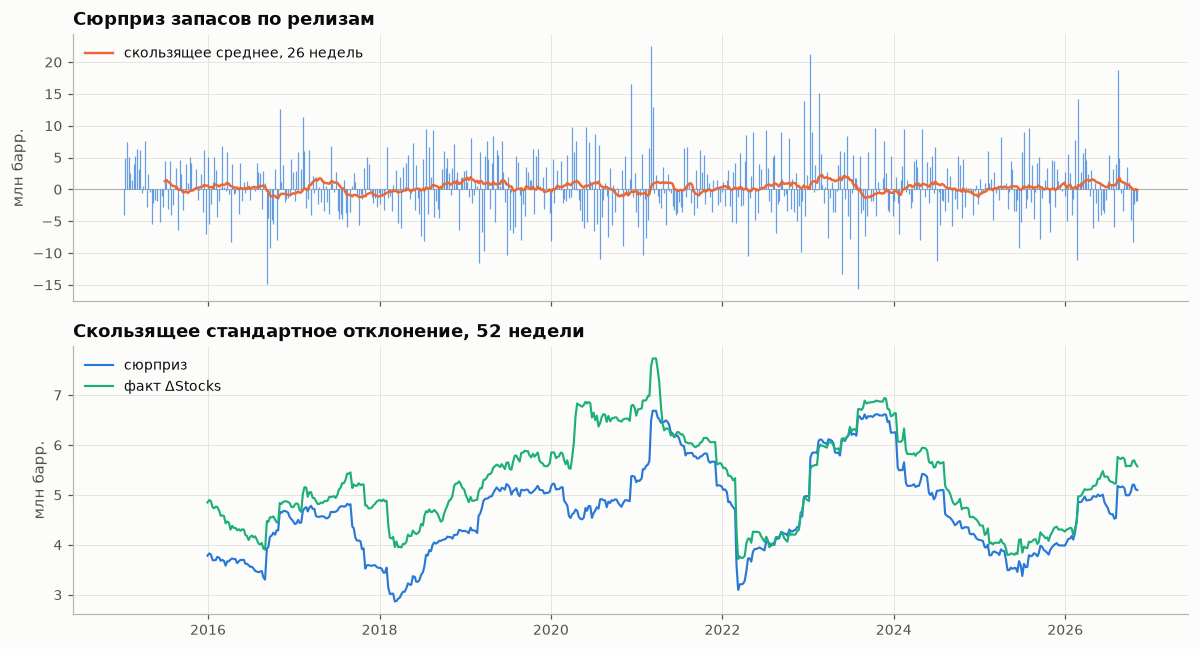

In [11]:
roll = frame.set_index("release_date")["surprise_mmbbl"]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].axhline(0, color=u.NEUTRAL, linewidth=0.8)
axes[0].vlines(roll.index, 0, roll, color=u.SERIES[0], linewidth=0.8, alpha=0.7)
axes[0].plot(roll.rolling(26).mean(), color=u.SERIES[1], linewidth=1.6, label="скользящее среднее, 26 недель")
axes[0].set_ylabel("млн барр.")
axes[0].set_title("Сюрприз запасов по релизам")
axes[0].legend(loc="upper left")
axes[1].plot(roll.rolling(52).std(), color=u.SERIES[0], label="сюрприз")
axes[1].plot(frame.set_index("release_date")["actual_mmbbl"].rolling(52).std(), color=u.SERIES[2], label="факт ΔStocks")
axes[1].set_ylabel("млн барр.")
axes[1].set_title("Скользящее стандартное отклонение, 52 недели")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

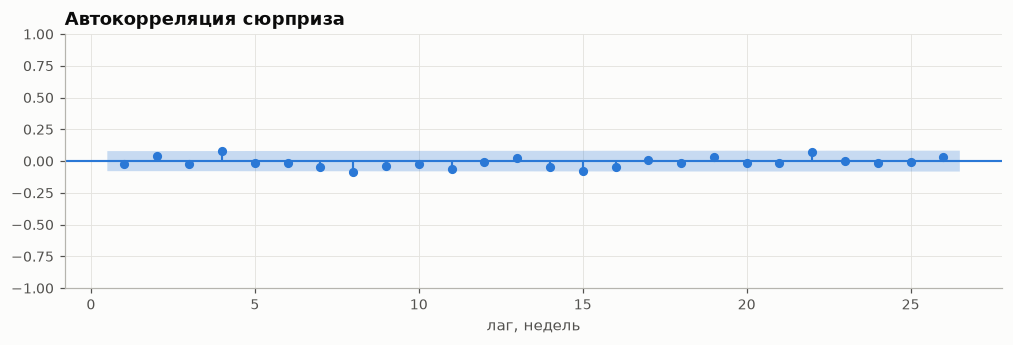

,Ljung–Box Q,p-value
1,0.2673,0.6051
4,5.7200,0.2211
13,16.0100,0.2486
26,27.2084,0.3985


In [12]:
fig, ax = plt.subplots(figsize=(11, 3))
plot_acf(s, lags=26, ax=ax, color=u.SERIES[0], vlines_kwargs={"colors": u.SERIES[0]}, zero=False)
ax.set_title("Автокорреляция сюрприза")
ax.set_xlabel("лаг, недель")
plt.show()
lb = acorr_ljungbox(s, lags=[1, 4, 13, 26])
lb.columns = ["Ljung–Box Q", "p-value"]
lb.round(4)

Различие по месяцам: ANOVA p = 0.257, Kruskal–Wallis p = 0.209


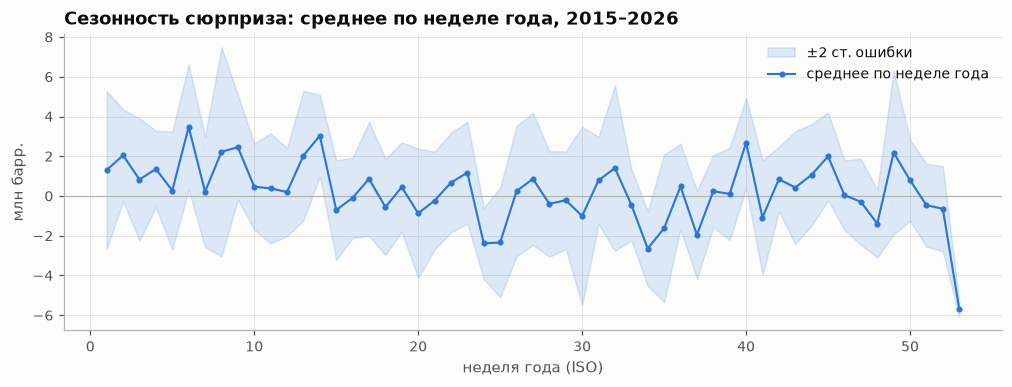

period,1,2,3,4,5,6,7,8,9,10,11,12
mean,1.16,1.56,1.21,0.61,-0.29,-0.69,-0.10,-0.40,-0.44,0.59,0.63,0.27
median,0.84,0.89,0.38,0.35,-0.90,-0.76,-0.43,-1.32,-0.05,0.21,0.46,-0.43
std,4.89,6.33,4.51,4.36,4.44,4.58,5.52,4.80,4.35,4.39,3.47,4.36
size,54.00,48.00,53.00,51.00,54.00,50.00,54.00,52.00,52.00,53.00,46.00,49.00


In [13]:
by_week = frame.groupby("week")["surprise_mmbbl"].agg(["mean", "std", "size"])
by_month = frame.groupby(frame["period"].dt.month)["surprise_mmbbl"].agg(["mean", "median", "std", "size"])
anova = stats.f_oneway(*[g.to_numpy() for _, g in frame.groupby(frame["period"].dt.month)["surprise_mmbbl"]])
kruskal = stats.kruskal(*[g.to_numpy() for _, g in frame.groupby(frame["period"].dt.month)["surprise_mmbbl"]])
print(f"Различие по месяцам: ANOVA p = {anova.pvalue:.3f}, Kruskal–Wallis p = {kruskal.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(11, 3.5))
se = by_week["std"] / np.sqrt(by_week["size"])
ax.axhline(0, color=u.NEUTRAL, linewidth=0.8)
ax.fill_between(by_week.index, by_week["mean"] - 2 * se, by_week["mean"] + 2 * se, color=u.SERIES[0], alpha=0.15, label="±2 ст. ошибки")
ax.plot(by_week.index, by_week["mean"], color=u.SERIES[0], marker="o", markersize=3, label="среднее по неделе года")
ax.set_xlabel("неделя года (ISO)")
ax.set_ylabel("млн барр.")
ax.set_title("Сезонность сюрприза: среднее по неделе года, 2015–2026")
ax.legend(loc="upper right")
plt.show()
by_month.round(2).T

**Вывод.** Среднее сюрприза +0.34 млн барр. (t = 1.77, p = 0.078 — на уровне 5% от нуля не
отличается), медиана 0.00, положительных ровно 50%. Хвосты толще нормальных: эксцесс 1.80,
асимметрия 0.41, Jarque–Bera p ≈ 4·10⁻²²; |сюрприз| > 5 млн барр. в 26% недель, > 10 — в 3.2%.
Автокорреляции нет (Ljung–Box p = 0.61, 0.22, 0.25, 0.40 на лагах 1, 4, 13, 26): по своему
прошлому сюрприз не предсказывается. Сезонность статистически незначима (ANOVA p = 0.26,
Kruskal–Wallis p = 0.21), но знак по месяцам устойчивый: январь–апрель в среднем от +0.6 до +1.6
(совпадает с сезоном ремонтов НПЗ), май–сентябрь от −0.1 до −0.7. Волатильность меняется по
годам: std от 3.5 (2017) до 6.3 (2023), поэтому MAE и RMSE сильно зависят от нескольких крупных
недель.

## 5. Насколько хорош консенсус как прогноз ΔStocks

Сравниваем прогнозы факта на test (2023+) с наивными: ноль, прошлая неделя, среднее по
неделе года за train-годы. API тоже прогноз факта, но выходит позже консенсуса.

In [14]:
train = frame[~frame["is_test"]]
seasonal = train.groupby("week")["actual_mmbbl"].mean()
frame["f_zero"] = 0.0
frame["f_last_week"] = frame["actual_mmbbl"].shift(1)
frame["f_seasonal"] = frame["week"].map(seasonal)
frame["f_consensus"] = frame["consensus_mmbbl"]
frame["f_api"] = frame["api_mmbbl"]


def scores(df: pd.DataFrame, target: str, forecasts: dict[str, str]) -> pd.DataFrame:
    """MAE, RMSE и точность знака для набора прогнозов."""

    rows = {}
    for name, column in forecasts.items():
        ok = df[[target, column]].dropna()
        err = ok[column] - ok[target]
        rows[name] = {
            "n": len(ok),
            "MAE": err.abs().mean(),
            "RMSE": np.sqrt((err**2).mean()),
            "точность знака": (np.sign(ok[column]) == np.sign(ok[target])).mean() if (ok[column] != 0).any() else np.nan,
            "corr": ok[column].corr(ok[target]) if ok[column].std() > 0 else np.nan,
        }
    return pd.DataFrame(rows).T


forecasts = {
    "ноль": "f_zero",
    "прошлая неделя": "f_last_week",
    "среднее по неделе года (train)": "f_seasonal",
    "консенсус Myfxbook": "f_consensus",
    "API (вторник)": "f_api",
}
print("Test, релизы с 2023-01-01:")
scores(frame[frame["is_test"]], "actual_mmbbl", forecasts).round(3)

Test, релизы с 2023-01-01:


,n,MAE,RMSE,точность знака,corr
ноль,200.0,4.151,5.332,NaN,NaN
прошлая неделя,200.0,5.242,6.902,0.565,0.162
среднее по неделе года (train),200.0,3.982,5.229,0.620,0.289
консенсус Myfxbook,200.0,3.673,4.996,0.665,0.360
API (вторник),200.0,2.870,3.588,0.795,0.763


In [15]:
print("Train, релизы до 2022-12-31 (для сравнения устойчивости):")
scores(frame[~frame["is_test"]], "actual_mmbbl", forecasts).round(3)

Train, релизы до 2022-12-31 (для сравнения устойчивости):


,n,MAE,RMSE,точность знака,corr
ноль,416.0,4.279,5.401,NaN,NaN
прошлая неделя,415.0,4.919,6.303,0.612,0.320
среднее по неделе года (train),416.0,3.655,4.704,0.688,0.491
консенсус Myfxbook,416.0,3.568,4.606,0.671,0.526
API (вторник),416.0,2.591,3.408,0.788,0.791


**Вывод.** На test (200 релизов с 2023 г.) консенсус лучше нулевого прогноза всего на 11.5%
по MAE (3.67 против 4.15) и ненамного лучше среднего по неделе года за train-годы (3.98); знак —
66.5% против 62.0%. Прогноз «как на прошлой неделе» хуже нуля (MAE 5.24): ΔStocks почти не
инерционен. Лучший прогноз факта — API, выходящий во вторник: MAE 2.87, знак 79.5%, corr 0.76.
На train порядок тот же. Консенсус — слабая планка, но API её уже заметно превосходит.

## 6. API: сигнал за день до EIA

API публикует своё изменение запасов во вторник в 16:30 ET, EIA — в среду в 10:30 ET.
Если `API − консенсус` предсказывает сюрприз, это сильнейший «бесплатный» признак —
и одновременно вопрос: когда фиксируется консенсус, до или после API?

Релизов с API: 616 из 616
corr(API, факт) = 0.782
corr(API − консенсус, сюрприз) = 0.715
совпадение знака (API − консенсус) и сюрприза: 73.5%
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.1096      0.134      0.821      0.412      -0.153       0.372
api_minus_consensus     0.7617      0.030     25.352      0.000       0.703       0.821
R² = 0.511


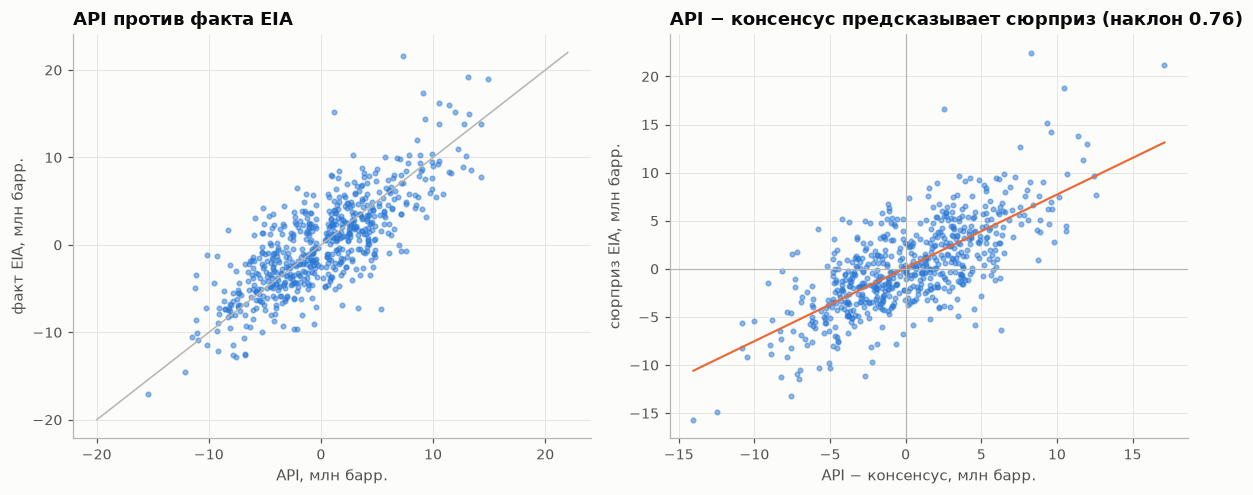

In [16]:
api = frame.dropna(subset=["api_mmbbl"]).copy()
api["api_minus_consensus"] = api["api_mmbbl"] - api["consensus_mmbbl"]
api["actual_minus_api"] = api["actual_mmbbl"] - api["api_mmbbl"]
print(f"Релизов с API: {len(api)} из {len(frame)}")
print(f"corr(API, факт) = {api['api_mmbbl'].corr(api['actual_mmbbl']):.3f}")
print(f"corr(API − консенсус, сюрприз) = {api['api_minus_consensus'].corr(api['surprise_mmbbl']):.3f}")
print(f"совпадение знака (API − консенсус) и сюрприза: {(np.sign(api['api_minus_consensus']) == np.sign(api['surprise_mmbbl'])).mean():.1%}")
ols_api = sm.OLS(api["surprise_mmbbl"], sm.add_constant(api["api_minus_consensus"])).fit()
print(ols_api.summary().tables[1])
print(f"R² = {ols_api.rsquared:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].scatter(api["api_mmbbl"], api["actual_mmbbl"], s=9, alpha=0.5, color=u.SERIES[0])
axes[0].plot((-20, 22), (-20, 22), color=u.NEUTRAL, linewidth=1)
axes[0].set_xlabel("API, млн барр.")
axes[0].set_ylabel("факт EIA, млн барр.")
axes[0].set_title("API против факта EIA")
axes[1].scatter(api["api_minus_consensus"], api["surprise_mmbbl"], s=9, alpha=0.5, color=u.SERIES[0])
g = np.linspace(api["api_minus_consensus"].min(), api["api_minus_consensus"].max(), 10)
axes[1].plot(g, ols_api.params["const"] + ols_api.params["api_minus_consensus"] * g, color=u.SERIES[1])
axes[1].axhline(0, color=u.NEUTRAL, linewidth=0.8)
axes[1].axvline(0, color=u.NEUTRAL, linewidth=0.8)
axes[1].set_xlabel("API − консенсус, млн барр.")
axes[1].set_ylabel("сюрприз EIA, млн барр.")
axes[1].set_title(f"API − консенсус предсказывает сюрприз (наклон {ols_api.params['api_minus_consensus']:.2f})")
plt.tight_layout()
plt.show()

In [17]:
by_year_api = api.groupby("year").apply(
    lambda g: pd.Series(
        {
            "corr(API, факт)": g["api_mmbbl"].corr(g["actual_mmbbl"]),
            "corr(API−конс., сюрприз)": g["api_minus_consensus"].corr(g["surprise_mmbbl"]),
            "знак совпал": (np.sign(g["api_minus_consensus"]) == np.sign(g["surprise_mmbbl"])).mean(),
            "MAE(факт − API)": g["actual_minus_api"].abs().mean(),
        },
    ),
    include_groups=False,
)
by_year_api.round(3)

,"corr(API, факт)","corr(API−конс., сюрприз)",знак совпал,MAE(факт − API)
year,,,,
2015,0.865,0.795,0.788,1.947
2016,0.768,0.741,0.750,2.479
2017,0.841,0.716,0.750,2.138
2018,0.614,0.466,0.615,3.612
2019,0.776,0.716,0.654,2.932
2020,0.815,0.699,0.792,2.887
2021,0.830,0.797,0.808,2.194
2022,0.787,0.795,0.765,2.536
2023,0.878,0.863,0.804,2.489


### Когда зафиксирован консенсус?

Если консенсус собирают после выхода API, он «подтягивается» к API: `|API − консенсус|`
будет систематически меньше `|факт − консенсус|`, а консенсус будет коррелировать с API
сильнее, чем с фактом. Если консенсус собран до API, такой подтяжки быть не должно.

In [18]:
print(f"corr(консенсус, API)  = {api['consensus_mmbbl'].corr(api['api_mmbbl']):.3f}")
print(f"corr(консенсус, факт) = {api['consensus_mmbbl'].corr(api['actual_mmbbl']):.3f}")
print(f"corr(API, факт)       = {api['api_mmbbl'].corr(api['actual_mmbbl']):.3f}")
print(f"медиана |API − консенсус| = {api['api_minus_consensus'].abs().median():.2f}; медиана |факт − консенсус| = {api['surprise_mmbbl'].abs().median():.2f}; медиана |факт − API| = {api['actual_minus_api'].abs().median():.2f}")
# Частичная корреляция консенсуса с API при фиксированном факте
resid_c = sm.OLS(api["consensus_mmbbl"], sm.add_constant(api["actual_mmbbl"])).fit().resid
resid_a = sm.OLS(api["api_mmbbl"], sm.add_constant(api["actual_mmbbl"])).fit().resid
print(f"частичная corr(консенсус, API | факт) = {np.corrcoef(resid_c, resid_a)[0, 1]:.3f}")

corr(консенсус, API)  = 0.495
corr(консенсус, факт) = 0.479
corr(API, факт)       = 0.782
медиана |API − консенсус| = 3.17; медиана |факт − консенсус| = 3.01; медиана |факт − API| = 2.24
частичная corr(консенсус, API | факт) = 0.219


**Вывод.** API есть для всех 616 релизов. corr(API, факт) = 0.78; `API − консенсус` объясняет
51% дисперсии сюрприза (наклон 0.76, R² = 0.51) и угадывает знак сюрприза в 73.5% недель. Связь
держится каждый год (corr от 0.47 в 2018 до 0.86 в 2023).

Признаков, что консенсус фиксируется после API, мало: с API он коррелирует (0.50) почти так же,
как с фактом (0.48), а медиана |API − консенсус| (3.17) не меньше медианы |факт − консенсус|
(3.01) — подтяжки к API нет. Частичная корреляция консенсуса и API при фиксированном факте 0.22:
общий компонент есть, но его можно объяснить общими исходными данными аналитиков и API. Время
фиксации консенсуса Myfxbook нужно проверить по источнику. Утечки будущего в признаке
`API − консенсус` нет в любом случае: API публикуется до EIA.

## 7. Предсказуем ли сюрприз по истории EIA (планка для M0)

Небольшая линейная модель на train, проверка на test. Признаки, известные до релиза:
лаги сюрприза, прошлый факт, сезонность (неделя года), прошлые изменения Cushing и
PADD3. Отдельно — та же модель плюс `API − консенсус` (аналог блока «+API» в M5).
Базовый прогноз сюрприза — ноль (консенсус несмещён).

In [19]:
eia = u.load("eia/eia_weekly_features.parquet")[["period", "cushing_stocks_change_mmbbl", "padd3_stocks_change_mmbbl", "refinery_utilization"]]
model = frame.merge(eia, on="period", how="left").sort_values("release_date")
for lag in (1, 2, 4):
    model[f"surprise_lag{lag}"] = model["surprise_mmbbl"].shift(lag)
model["actual_lag1"] = model["actual_mmbbl"].shift(1)
# Изменения прошлой недели: известны к текущему релизу
model["cushing_lag1"] = model["cushing_stocks_change_mmbbl"].shift(1)
model["padd3_lag1"] = model["padd3_stocks_change_mmbbl"].shift(1)
model["util_lag1"] = model["refinery_utilization"].shift(1)
model["week_sin"] = np.sin(2 * np.pi * model["week"] / 52.18)
model["week_cos"] = np.cos(2 * np.pi * model["week"] / 52.18)
model["api_minus_consensus"] = model["api_mmbbl"] - model["consensus_mmbbl"]

history = ["surprise_lag1", "surprise_lag2", "surprise_lag4", "actual_lag1", "cushing_lag1", "padd3_lag1", "util_lag1", "week_sin", "week_cos", "consensus_mmbbl"]
data = model.dropna(subset=[*history, "api_minus_consensus", "surprise_mmbbl"])
tr, te = data[~data["is_test"]], data[data["is_test"]]


def evaluate(features: list[str]) -> tuple[dict, pd.Series]:
    """OLS на train, метрики на test."""

    fitted = sm.OLS(tr["surprise_mmbbl"], sm.add_constant(tr[features])).fit()
    pred = fitted.predict(sm.add_constant(te[features]))
    err = pred - te["surprise_mmbbl"]
    return {
        "MAE": err.abs().mean(),
        "RMSE": np.sqrt((err**2).mean()),
        "точность знака": (np.sign(pred) == np.sign(te["surprise_mmbbl"])).mean(),
        "corr": pred.corr(te["surprise_mmbbl"]),
    }, fitted.params


zero_err = te["surprise_mmbbl"].abs()
results = {
    "ноль": {"MAE": zero_err.mean(), "RMSE": np.sqrt((te["surprise_mmbbl"] ** 2).mean()), "точность знака": np.nan, "corr": np.nan},
}
results["история EIA"], params_hist = evaluate(history)
results["только API − консенсус"], params_api = evaluate(["api_minus_consensus"])
results["история EIA + API − консенсус"], params_full = evaluate([*history, "api_minus_consensus"])
print(f"train: {len(tr)} релизов, test: {len(te)} релизов")
pd.DataFrame(results).T.round(3)

train: 407 релизов, test: 200 релизов


,MAE,RMSE,точность знака,corr
ноль,3.673,4.996,NaN,NaN
история EIA,3.658,4.942,0.525,0.136
только API − консенсус,2.696,3.425,0.730,0.726
история EIA + API − консенсус,2.668,3.410,0.720,0.729


In [20]:
params_full.round(3).to_frame("коэффициент (история + API)")

,коэффициент (история + API)
const,3.293
surprise_lag1,0.291
surprise_lag2,0.017
surprise_lag4,-0.022
actual_lag1,-0.352
cushing_lag1,0.233
padd3_lag1,-0.026
util_lag1,-0.036
week_sin,0.187
week_cos,0.216


**Вывод.** Модель на истории EIA (лаги сюрприза, прошлый факт, Cushing и PADD3 прошлой недели,
загрузка НПЗ, сезонность, консенсус) на test не лучше нуля: MAE 3.66 против 3.67, corr 0.14,
знак 52.5%. Один признак `API − консенсус` снижает MAE на 27% (2.70), corr 0.73, знак 73%;
история EIA поверх API почти ничего не добавляет (2.67). Значит: (1) планка M0 почти совпадает с
нулевым прогнозом; (2) информация о сюрпризе вне истории EIA существует, и самый сильный
известный её источник — API; (3) прирост от новостей (M3, M5) надо мерить против базовой модели
с API, иначе новости могут просто пересказывать API.

## Итоги

**Главное**

- Таргет: 616 релизов 2015-01 – 2026-11; неделя отчёта — «пятница не позже релиза минус 5 дней»;
  в Myfxbook нет недель 2022-06-17 и 2023-11-03.
- Факт — из первой публикации (Myfxbook): с текущими данными EIA расходится в 17 неделях,
  в 6 из них на 0.5 млн барр. и больше.
- Сюрприз: среднее ≈ 0 (p = 0.078), толстые хвосты (эксцесс 1.8), без автокорреляции и без
  значимой сезонности — для моделей на истории EIA это почти белый шум.
- Консенсус слабый и теряет информативность: R² = 0.23 за весь период, corr с фактом 0.35–0.39
  в 2023–2026.
- API (вторник, 16:30 ET): `API − консенсус` объясняет 51% дисперсии сюрприза, знак — 73.5%;
  это лучший прогноз факта (MAE 2.87 на test против 3.67 у консенсуса).
- M0 на истории EIA ≈ нулевой прогноз; `API − консенсус` даёт −27% MAE.

**Качество данных**

- Две пропущенные недели отчёта в Myfxbook (2022-06-17, 2023-11-03).
- 2022-06-29: первая публикация −0.39 против −2.76 в текущих данных EIA — сверить вручную.
- 9 релизов без пересмотренного значения EIA: 7 до начала `eia_weekly_features` (2015-02-20),
  первая неделя ряда (изменение не посчитать) и последний релиз 2026-11-04.
- Консенсус — смесь круглых и усреднённых значений (кратны 0.1 только 33%): методика источника
  могла меняться.

**Для моделирования**

- Включить `API − консенсус` в базовые модели (M0/M4), иначе вклад новостей будет переоценён.
- Кроме MAE/RMSE — медианная ошибка, точность знака и отдельный разбор недель с |сюрприз| > 5.
- Лаговые признаки факта — из первой публикации.
- Волатильность и информативность консенсуса дрейфуют по годам: валидировать скользящим окном
  (walk-forward), а не одним разбиением.
- Проверить время фиксации консенсуса Myfxbook.